# Football Managerial Decision Analytics — Chapter 02
## Match, team and player performance

> **Data.** StatsBomb Open Data (https://github.com/hudl/open-data), provided by StatsBomb / Hudl, used for educational, non-commercial research. Raw data are downloaded from the official repository at run time and are not redistributed here. Every figure carries its chart ID from `docs/VISUALIZATION_CATALOGUE.md`.

This notebook is one chapter of the research record. All logic lives in the shared `src/` package; the cells call it. The same charts are available interactively in the Streamlit dashboard (`streamlit run app.py`).

In [1]:
# Setup — locate (or fetch) the project code, import the shared package, load the workspace
import os, subprocess, sys, time
from pathlib import Path

REPO_URL = "https://github.com/blazingarrows1525/football-managerial-decision-analytics"
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "workspace.py").exists()), None)
if ROOT is None:  # opened on its own (e.g. Google Colab): fetch the project code once, next to this notebook
    ROOT = Path.cwd() / "football-managerial-decision-analytics"
    if not (ROOT / "src" / "workspace.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements.txt")], check=True)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("FMA_PROJECT_ROOT", str(ROOT))  # data cache and outputs live inside the project folder

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src.reporting.notebook_tools import (catalogue, explorer, implication, interpret, limitation, show, start,
                                          timed, timings)

pd.set_option("display.max_columns", 40, "display.width", 200, "display.float_format", "{:.3f}".format)
RUN_ADVANCED_GALLERY = True   # heavier, optional sections; the core story does not depend on them
SEED = 42                             # every resampling and model step takes this seed explicitly

ws = start(seed=SEED)                 # first run downloads and parses; later runs read the processed cache
B, T, FOCUS = ws.bundle, ws.tables, ws.focus
tm = ws.team_matches()                # the focus team's matches in date order
print(f"Advanced sections: {'on' if RUN_ADVANCED_GALLERY else 'off'} · Python {sys.version.split()[0]} · pandas {pd.__version__}")

**Workspace ready in 2.7s** (processed cache) · 1. Bundesliga 2023/2024 · 34 matches · 137,765 events · focus team **Bayer Leverkusen** · figures: static PNG (FMA_STATIC=1) · seed 42

Advanced sections: on · Python 3.10.11 · pandas 2.1.4


## D · Match, team and player performance

**Research question.** How did the team perform, how much of it is explained by chance quality, and which
players drive it?

**Data and method.** Team match statistics (goals, StatsBomb xG, shots, pass-share possession proxy, field
tilt, PPDA) and player season tables with per-90 rates and role percentiles. Expected points simulate each shot
as a Bernoulli trial with its xG.

,matches,W-D-L,points,expected points,goals,xG,players used
0,34,28-6-0,90.000,74.800,89-24,72.7-27.8,24


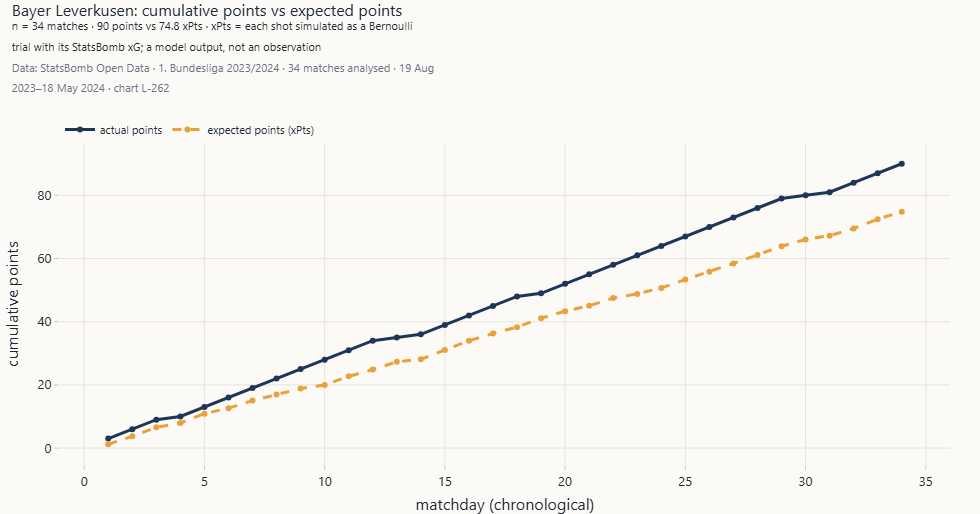

`L-262` Points versus expected points · *Method:* Shot-level Bernoulli simulation (5,000 runs per match). · *Caveat:* xPts is a model output.

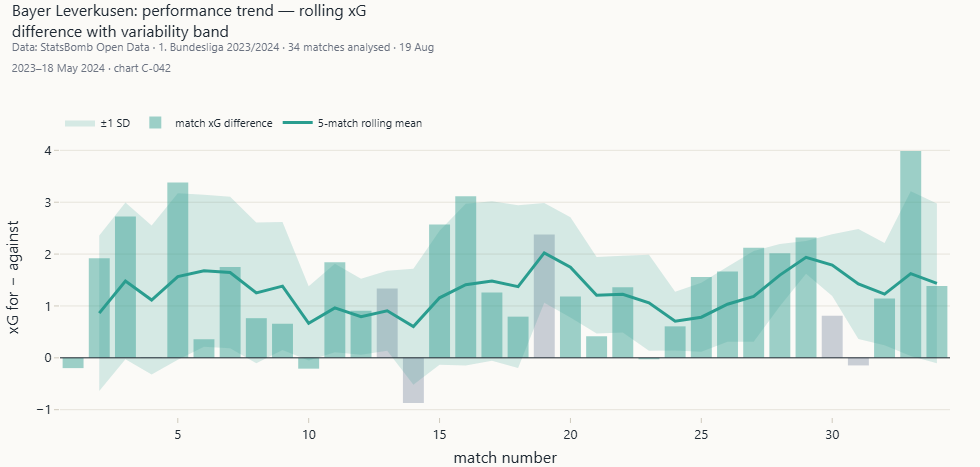

`C-042` Rolling performance form · *Method:* 5-match rolling xG difference with a ±1 SD band.

**Interpretation.** Bayer Leverkusen took 90 points from 34 matches against 74.8 expected from shot quality — 15.2 more than the simulation — and scored 89 goals from 72.7 xG. Mean xG difference per match: +1.32.

**Managerial implication.** Judge performances on chances created and conceded; the points total alone flatters or punishes a team for finishing and goalkeeping variance.

**Limitation.** Expected points are a model output: shots are treated as independent and game state is ignored.

In [2]:
from src.analytics import descriptive as desc
k = desc.season_kpis(B, FOCUS)
xp = ws.xpts(); xp = xp[xp.team_name == FOCUS]
display(pd.DataFrame([{"matches": k["matches"], "W-D-L": f"{k['wins']}-{k['draws']}-{k['losses']}", "points": k["points"],
                       "expected points": round(xp.xpts.sum(), 1), "goals": f"{k['goals_for']}-{k['goals_against']}",
                       "xG": f"{k['xg_for']:.1f}-{k['xg_against']:.1f}", "players used": k["players_used"]}]))
show("L-262", ws)
show("C-042", ws)
gap = k["points"] - xp.xpts.sum()
interpret(f"{FOCUS} took {k['points']:.0f} points from {k['matches']} matches against {xp.xpts.sum():.1f} expected from shot "
          f"quality — {abs(gap):.1f} {'more' if gap > 0 else 'fewer'} than the simulation — and scored {k['goals_for']} "
          f"goals from {k['xg_for']:.1f} xG. Mean xG difference per match: {tm.xg_diff.mean():+.2f}.")
implication("Judge performances on chances created and conceded; the points total alone flatters or punishes a "
            "team for finishing and goalkeeping variance.")
limitation("Expected points are a model output: shots are treated as independent and game state is ignored.")

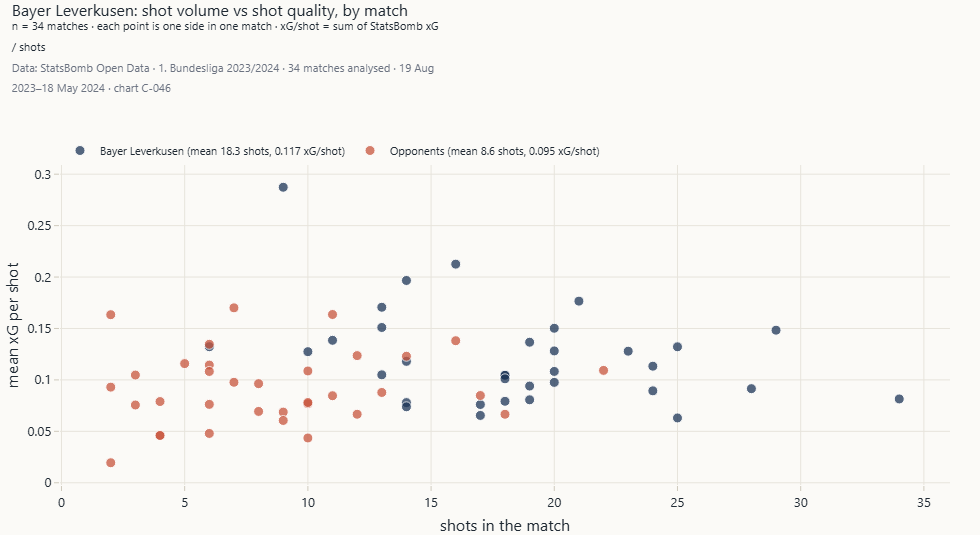

`C-046` Shot volume versus shot quality · *Method:* Shots vs mean xG per shot, team and opponents.

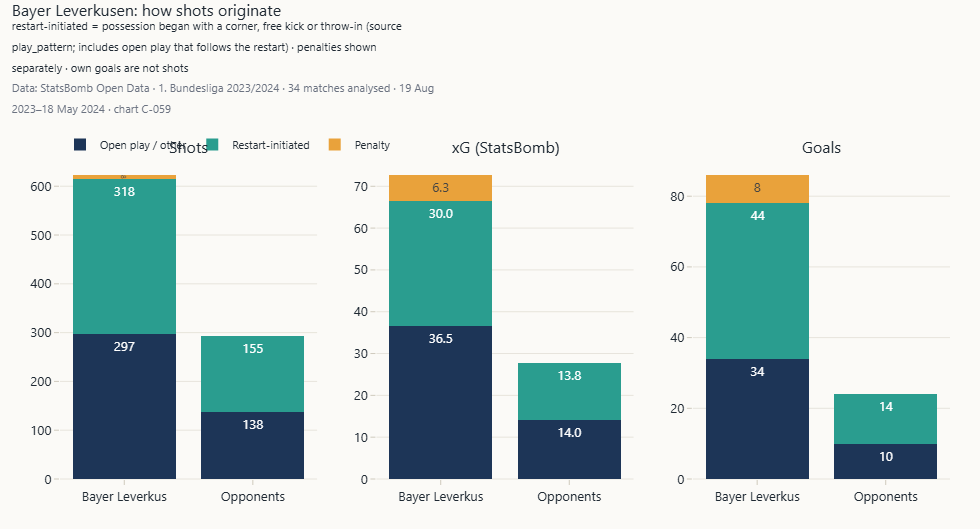

`C-059` Set-piece versus open-play contribution · *Method:* Shots, xG and goals by how the possession started.

**Interpretation.** Bayer Leverkusen took 623 shots against 293 for opponents; xG per shot was 0.117 against 0.095. The gap in **volume** is far larger than the gap in **quality**. Possessions that began with a corner, free kick or throw-in produced 44 of the team's goals from shots.

In [3]:
show("C-046", ws)
show("C-059", ws)
split = desc.shot_origin_split(B, FOCUS).set_index(["side", "origin"])
f = split.loc["for"]; a = split.loc["against"]
interpret(f"{FOCUS} took {int(f.shots.sum())} shots against {int(a.shots.sum())} for opponents; xG per shot was "
          f"{f.xg.sum() / f.shots.sum():.3f} against {a.xg.sum() / a.shots.sum():.3f}. The gap in **volume** is far larger than "
          f"the gap in **quality**. Possessions that began with a corner, free kick or throw-in produced "
          f"{int(f.loc['Restart-initiated', 'goals'])} of the team's goals from shots.")

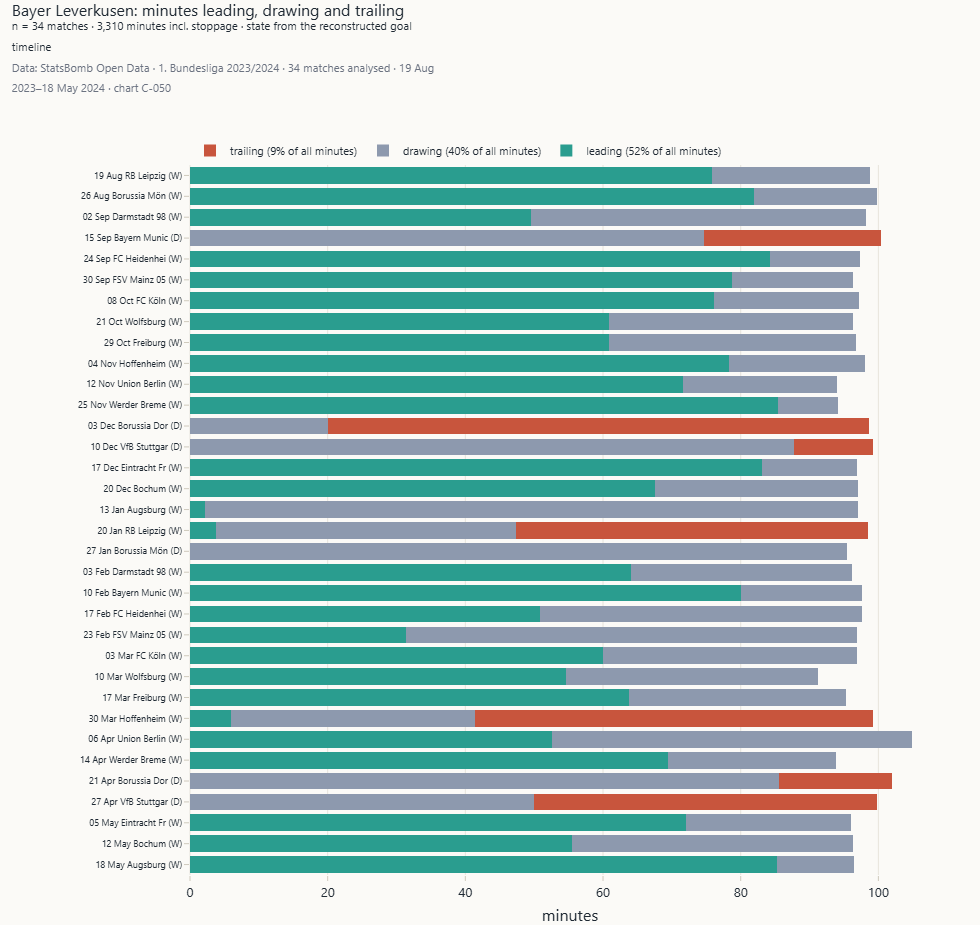

`C-050` Score-state time share · *Method:* Minutes per state from the reconstructed goal timeline.

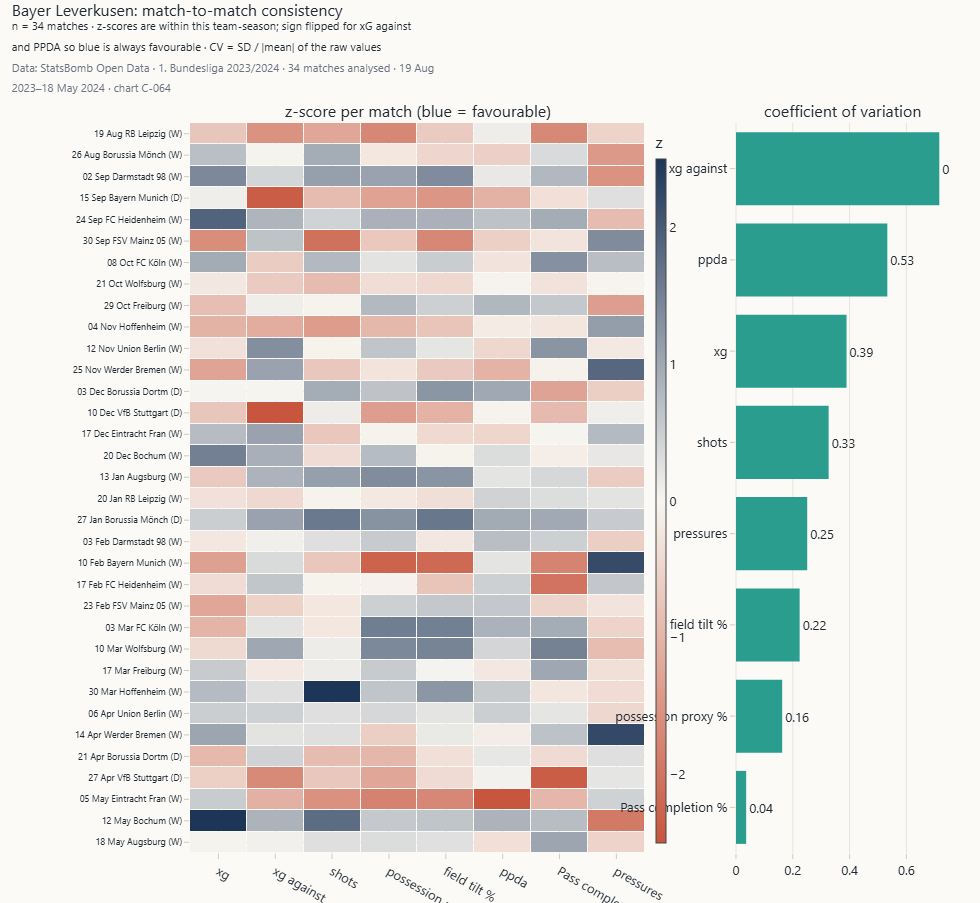

`C-064` Team consistency heatmap · *Method:* Within-season z-scores and coefficient of variation.

**Interpretation.** The team spent 52% of its minutes leading, 40% level and 9% behind. The most stable match metrics are pass_completion_pct (CV 0.04) and possession_proxy_pct (0.16); the most volatile are xg_against (0.72) and ppda (0.53).

**Managerial implication.** Swings in the volatile metrics are normal match-to-match noise; persistent change in the stable ones is the earlier warning sign.

In [4]:
show("C-050", ws)
show("C-064", ws)
st_time = ws.state_time()
tot = st_time[["leading", "drawing", "trailing"]].sum()
z, cv = desc.team_consistency(B, FOCUS)
interpret(f"The team spent {tot.leading / tot.sum():.0%} of its minutes leading, {tot.drawing / tot.sum():.0%} level and "
          f"{tot.trailing / tot.sum():.0%} behind. The most stable match metrics are {cv.index[0]} (CV {cv.iloc[0]:.2f}) and "
          f"{cv.index[1]} ({cv.iloc[1]:.2f}); the most volatile are {cv.index[-1]} ({cv.iloc[-1]:.2f}) and {cv.index[-2]} ({cv.iloc[-2]:.2f}).")
implication("Swings in the volatile metrics are normal match-to-match noise; persistent change in the stable "
            "ones is the earlier warning sign.")

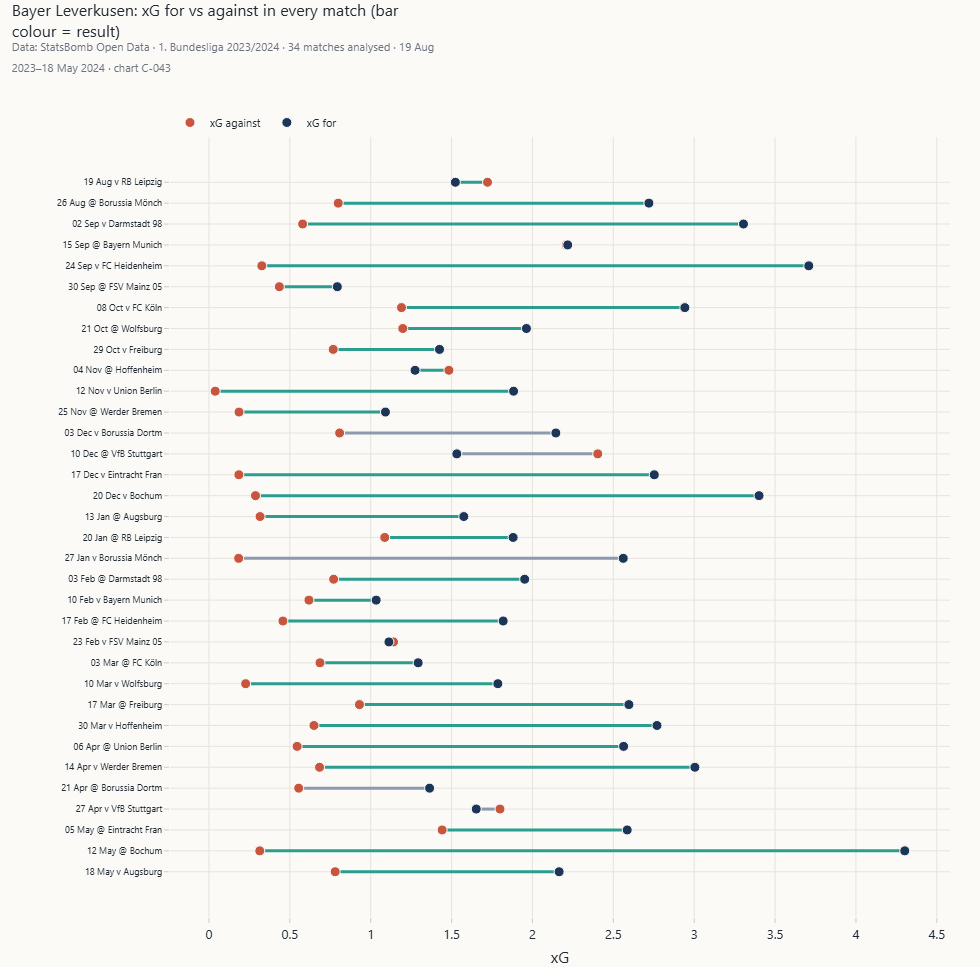

`C-043` Match-level xG for and against · *Method:* Dumbbell per match.

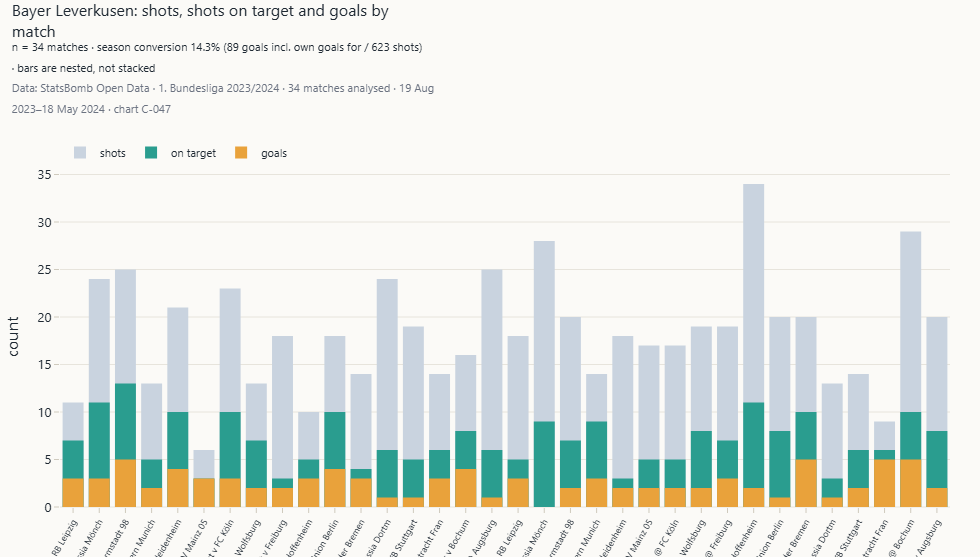

`C-047` Shot count and conversion by match · *Method:* Nested bars.

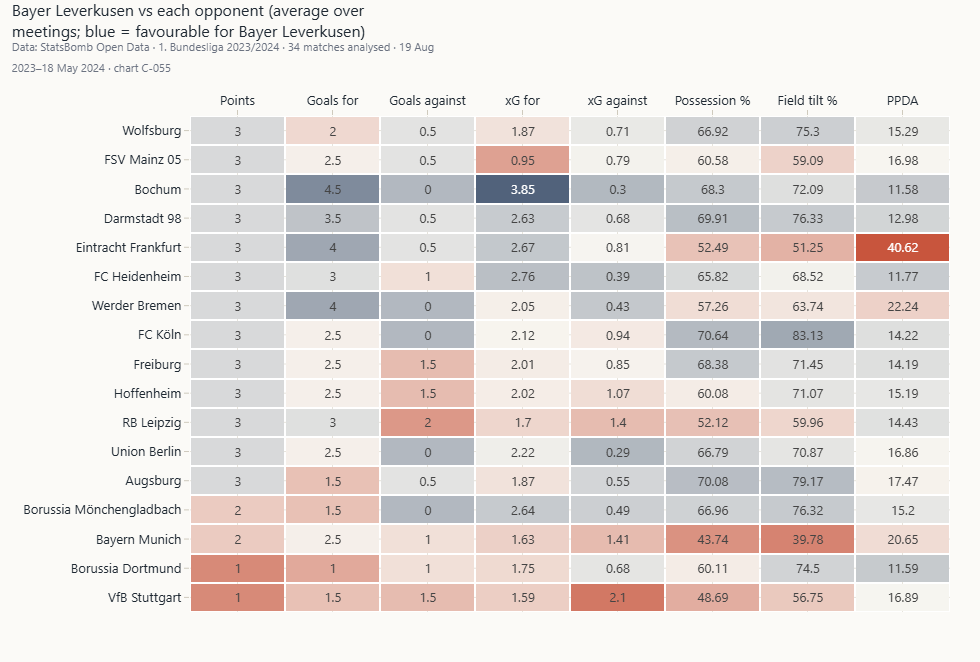

`C-055` Opponent matrix · *Method:* Opponent × metric, average over meetings. · *Caveat:* Two meetings per opponent.

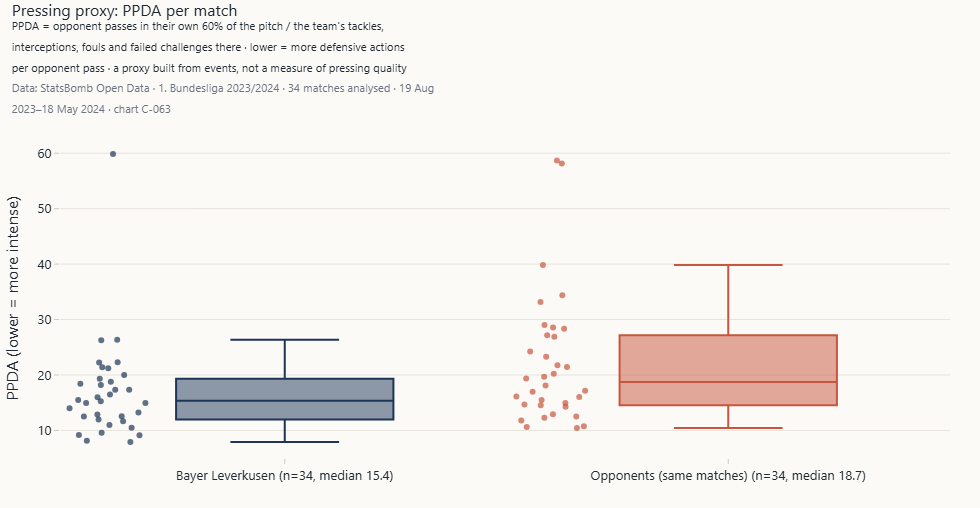

`C-063` Pressing proxy (PPDA) distribution · *Method:* Opponent passes in their own 60% / the team's defensive actions there. · *Caveat:* An event-based proxy; formula validated against event coverage.

In [5]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    show("C-043", ws)
    show("C-047", ws)
    show("C-055", ws)
    show("C-063", ws)

### One match in detail

**Question.** What happened, in order, in a representative match? The default is the match with the median xG
difference — neither the best nor the worst.

03 Dec 2023: Bayer Leverkusen 1-1 Borussia Dortmund


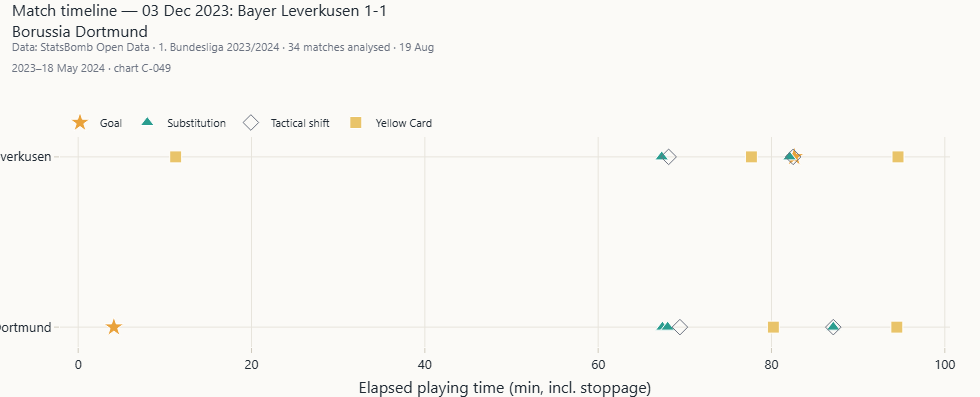

`C-049` Goal and event timeline of a match · *Method:* Goals, cards and substitutions on the elapsed clock.

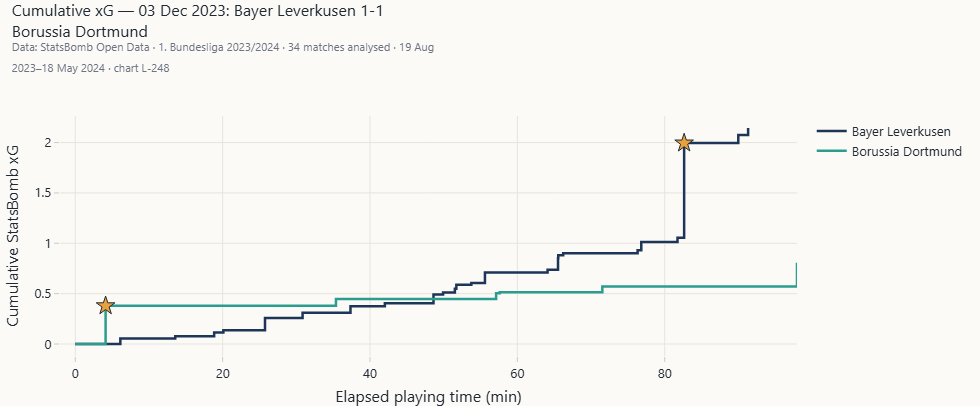

`L-248` Cumulative xG of a match · *Method:* Step chart of StatsBomb xG by team.

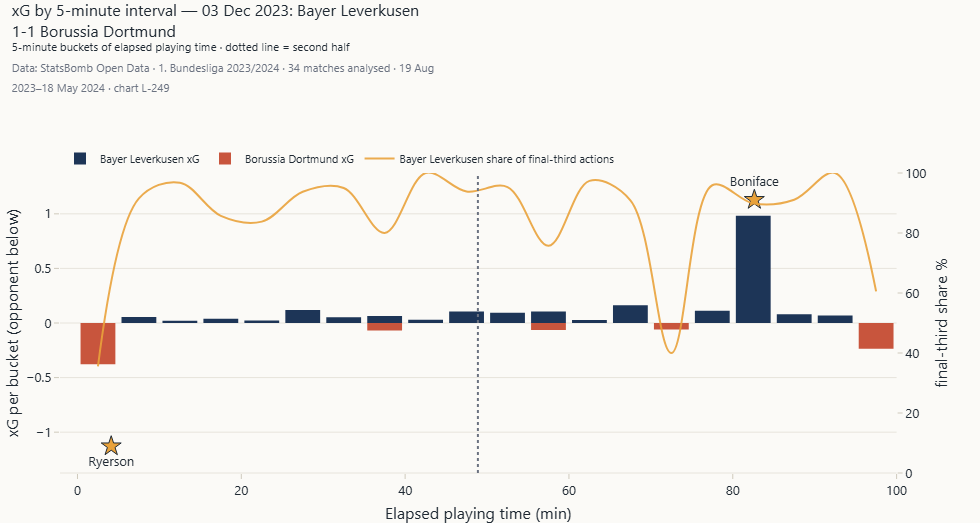

`L-249` Match xG-by-interval chart · *Method:* xG per 5-minute bucket for each side, with final-third touch share. · *Caveat:* This is xG per interval, not a validated momentum measure.

**Limitation.** The interval chart is xG per five minutes — a description of when chances occurred, not a validated momentum measure.

In [6]:
mid = ws.default_match()
print(ws.match_label(mid))
show("C-049", ws, match_id=mid)
show("L-248", ws, match_id=mid)
show("L-249", ws, match_id=mid)
limitation("The interval chart is xG per five minutes — a description of when chances occurred, not a validated "
           "momentum measure.")

### Players

**Question.** Who contributes what, relative to players of the same role, and how certain is it?

,player_name,primary_position,minutes_played,starts,goals,xg,assists,xa,xg_p90,xa_p90,progressive_passes_p90,benchmark_group,benchmark_n,coverage_label
0,Lukáš Hrádecký,Goalkeeper,3214.600,33,0.000,0.000,0.000,0.000,0.000,0.000,0.000,GK,14.000,high data coverage
1,Granit Xhaka,Right Defensive Midfield,3034.767,32,3.000,1.571,0.000,2.606,0.047,0.077,4.893,DM,14.000,high data coverage
2,Álex Grimaldo,Left Wing Back,2994.683,31,10.000,5.209,13.000,9.148,0.157,0.275,4.268,Defender,38.000,high data coverage
3,Jonathan Tah,Center Back,2848.117,30,4.000,1.806,1.000,0.326,0.057,0.010,2.022,CB,22.000,high data coverage
4,Florian Wirtz,Left Attacking Midfield,2528.867,26,11.000,8.471,10.000,7.733,0.301,0.275,7.153,Midfielder,22.000,high data coverage
5,Jeremie Frimpong,Right Wing Back,2378.467,27,9.000,8.720,7.000,4.543,0.330,0.172,2.762,Defender,38.000,high data coverage
6,Jonas Hofmann,Right Attacking Midfield,2334.683,26,4.000,5.709,7.000,7.839,0.220,0.302,3.392,Midfielder,22.000,high data coverage
7,Edmond Fayçal Tapsoba,Left Center Back,2262.517,23,0.000,1.009,1.000,0.652,0.040,0.026,4.057,CB,22.000,high data coverage
8,Odilon Kossonou,Right Center Back,1962.233,21,1.000,0.388,0.000,0.875,0.018,0.040,2.935,CB,22.000,high data coverage
9,Exequiel Palacios,Left Defensive Midfield,1949.783,21,4.000,2.694,4.000,3.334,0.124,0.154,4.616,DM,14.000,high data coverage


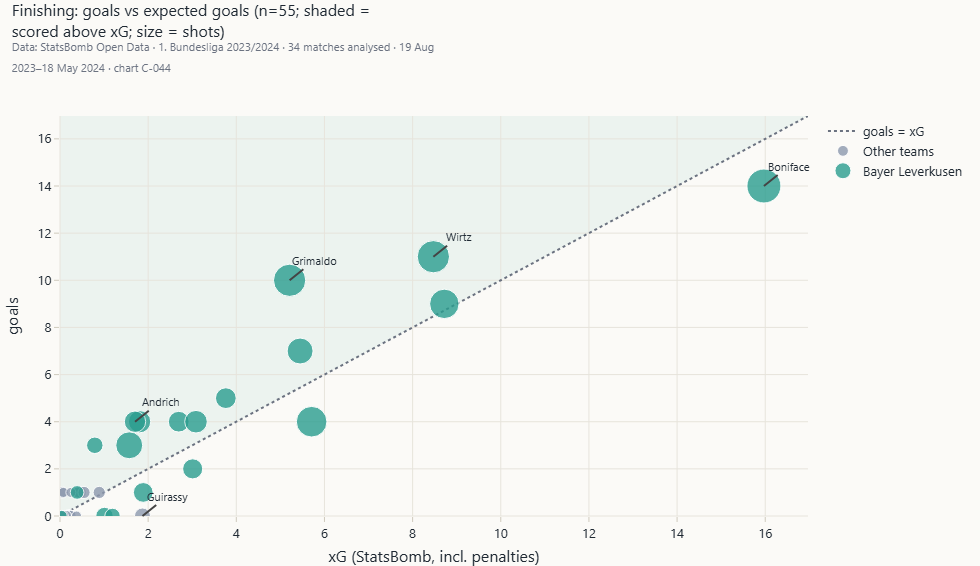

`C-044` Goals versus xG · *Method:* Goals against xG per player. · *Caveat:* Finishing over- or under-performance regresses strongly.

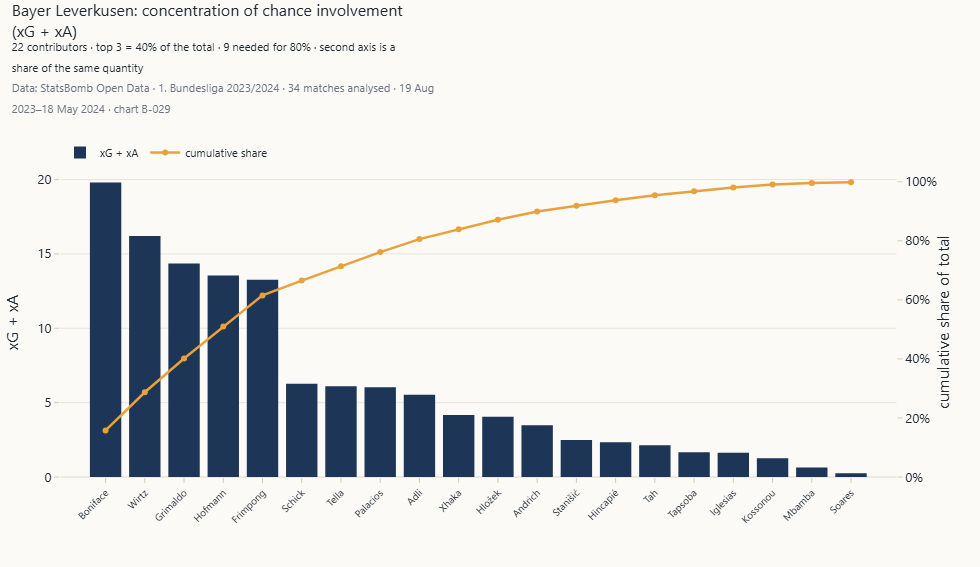

`B-029` Pareto / concentration chart · *Method:* Sorted xG + xA with cumulative share. · *Caveat:* xA is credited to the passer of a shot assist.

**Interpretation.** The top three contributors (Victor Boniface, Florian Wirtz, Álex Grimaldo) account for 40% of the squad's xG + xA; 9 players are needed to reach 80%. Gini coefficient 0.52.

**Managerial implication.** Like-for-like cover and minutes management matter most for the few players who create the chances.

In [7]:
sq = ws.squad()
display(sq[["player_name", "primary_position", "minutes_played", "starts", "goals", "xg", "assists", "xa", "xg_p90", "xa_p90",
            "progressive_passes_p90", "benchmark_group", "benchmark_n", "coverage_label"]].head(14))
show("C-044", ws)
show("B-029", ws)
conc = desc.concentration(sq.set_index("player_name").eval("xg + xa"))
interpret(f"The top three contributors ({', '.join(conc.label.head(3))}) account for {conc.share.head(3).sum():.0%} of the "
          f"squad's xG + xA; {int((conc.cumulative_share < 0.8).sum() + 1)} players are needed to reach 80%. "
          f"Gini coefficient {desc.gini(conc.value):.2f}.")
implication("Like-for-like cover and minutes management matter most for the few players who create the chances.")

Example player: Granit Xhaka


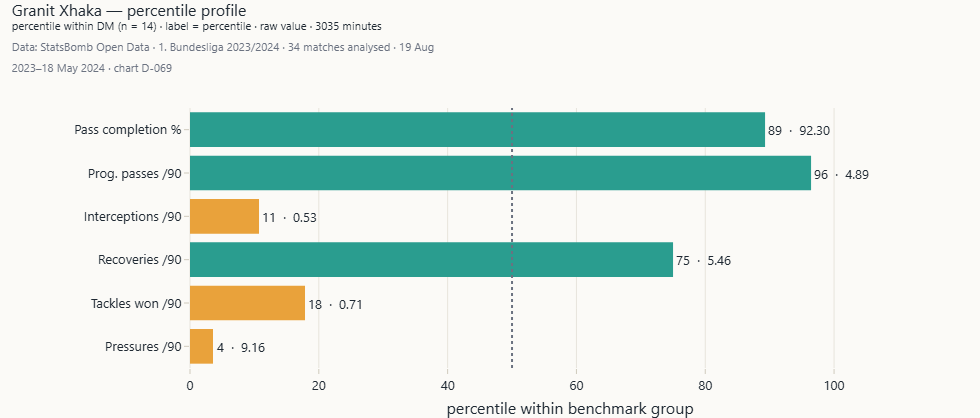

`D-069` Percentile chart by role group · *Method:* Percentile within the benchmark group, with group size.

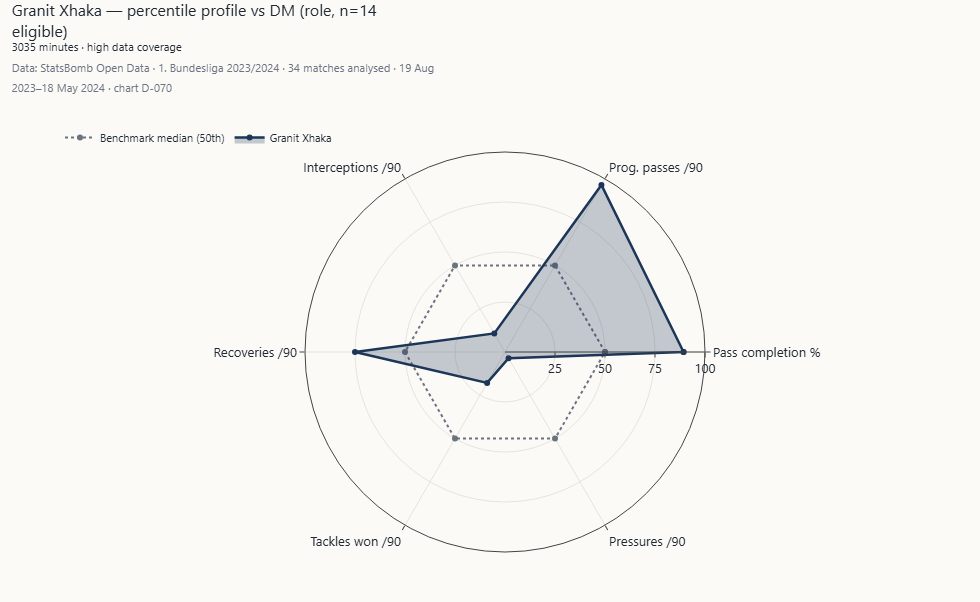

`D-070` Player radar · *Method:* Role metrics as percentiles; all axes higher = higher percentile.

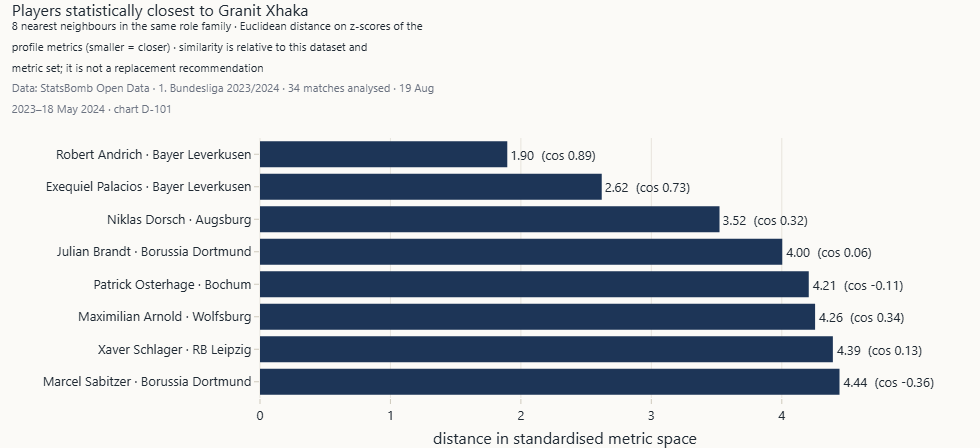

`D-101` Player similarity map · *Method:* Euclidean distance on z-scores within the role family. · *Caveat:* Depends on the metric set and the standardisation sample.

**Limitation.** Similarity is distance in standardised per-90 space within this dataset; it is not a replacement recommendation.

In [8]:
pid = ws.default_player()
print("Example player:", ws.player_name(pid))
show("D-069", ws, player_id=pid)
show("D-070", ws, player_id=pid)
show("D-101", ws, player_id=pid)
limitation("Similarity is distance in standardised per-90 space within this dataset; it is not a replacement "
           "recommendation.")

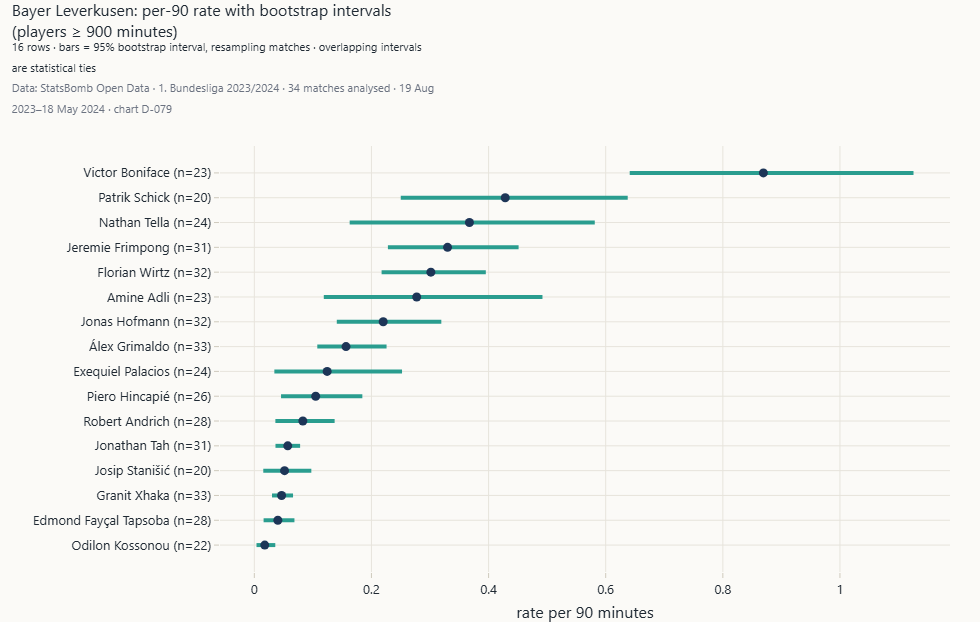

`D-079` Bootstrap confidence intervals per player · *Method:* 2,000 bootstrap resamples of each player's matches.

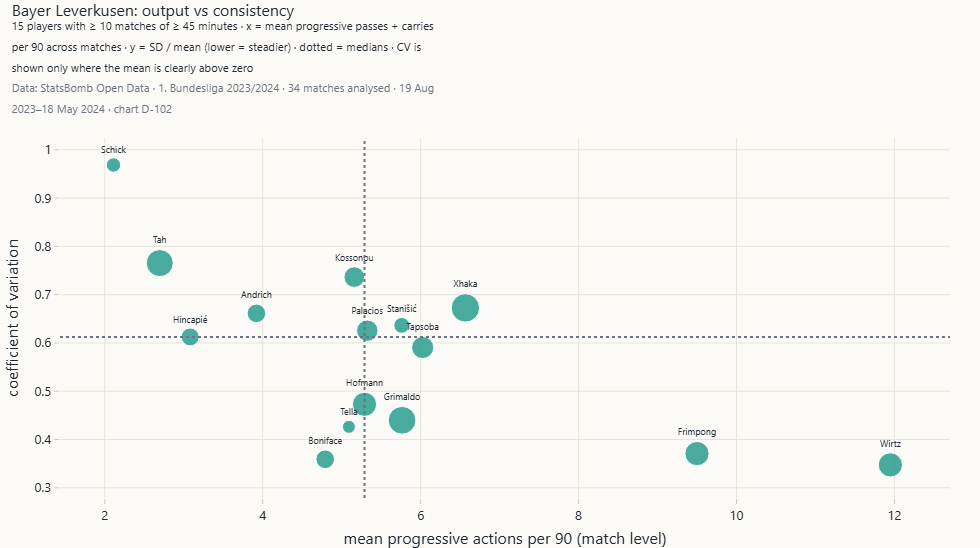

`D-102` Consistency versus output quadrant · *Method:* Mean progressive actions/90 vs coefficient of variation.

**Interpretation.** Victor Boniface leads on xG per 90 (0.87, 95% bootstrap interval 0.64–1.13), which is clearly separated from Patrik Schick (0.25–0.64). Among above-median progressors Florian Wirtz is the steadiest (CV 0.35 at 11.9 progressive actions per 90).

**Managerial implication.** Rank attackers in tiers. Inside overlapping intervals the order is not established by one season.

In [9]:
from src.analytics import uncertainty as unc
reg = sq[(sq.minutes_played >= 900) & (sq.primary_role != "GK")]
ci = unc.bootstrap_rate_intervals(B.pms, reg, "xg", seed=SEED)
show("D-079", ws, metric="xg_p90")
show("D-102", ws)
top, second = ci.iloc[-1], ci.iloc[-2]
sep = "is clearly separated from" if second.hi < top.lo else "overlaps with"
cons = ws.consistency()
steady = cons[cons.prog_mean > cons.prog_mean.median()].sort_values("prog_cv").iloc[0]
interpret(f"{top.player} leads on xG per 90 ({top.rate_p90:.2f}, 95% bootstrap interval {top.lo:.2f}–{top.hi:.2f}), which {sep} "
          f"{second.player} ({second.lo:.2f}–{second.hi:.2f}). Among above-median progressors {steady.player_name} is the "
          f"steadiest (CV {steady.prog_cv:.2f} at {steady.prog_mean:.1f} progressive actions per 90).")
implication("Rank attackers in tiers. Inside overlapping intervals the order is not established by one season.")

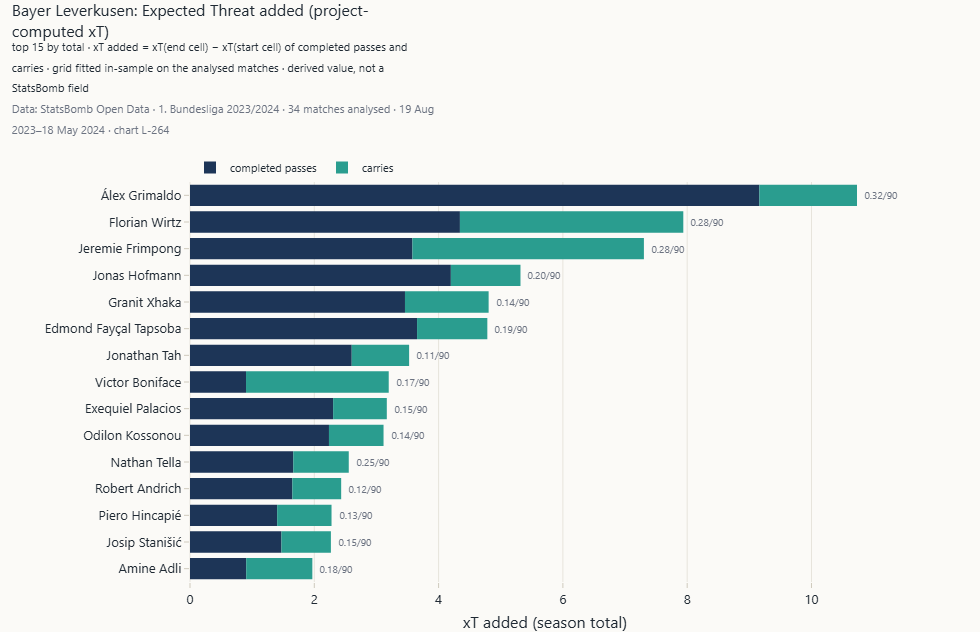

`L-264` xT added by player · *Method:* xT(end) − xT(start) of completed passes and carries. · *Caveat:* Derived project value on an in-sample grid.

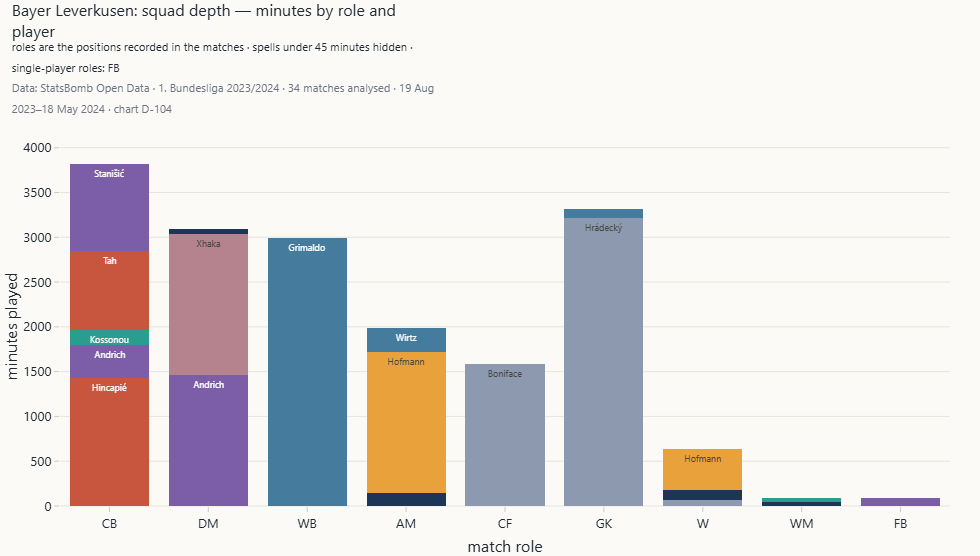

`D-104` Squad depth chart · *Method:* Minutes by role and player.

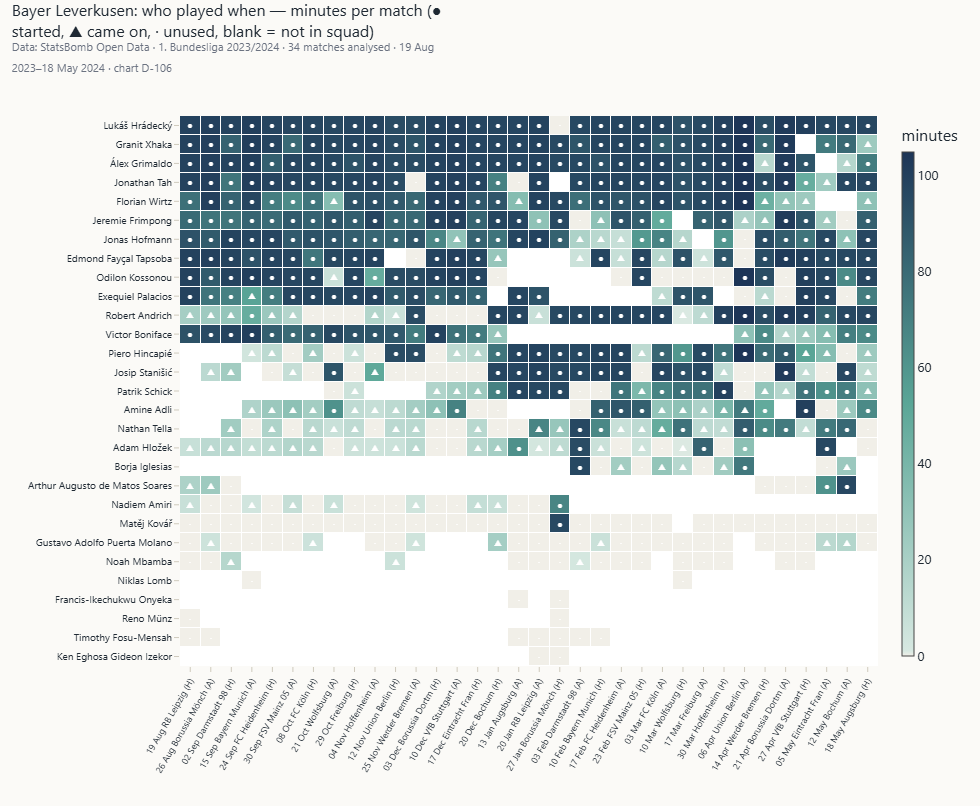

`D-106` Rotation / appearance calendar · *Method:* Player × match minutes matrix.

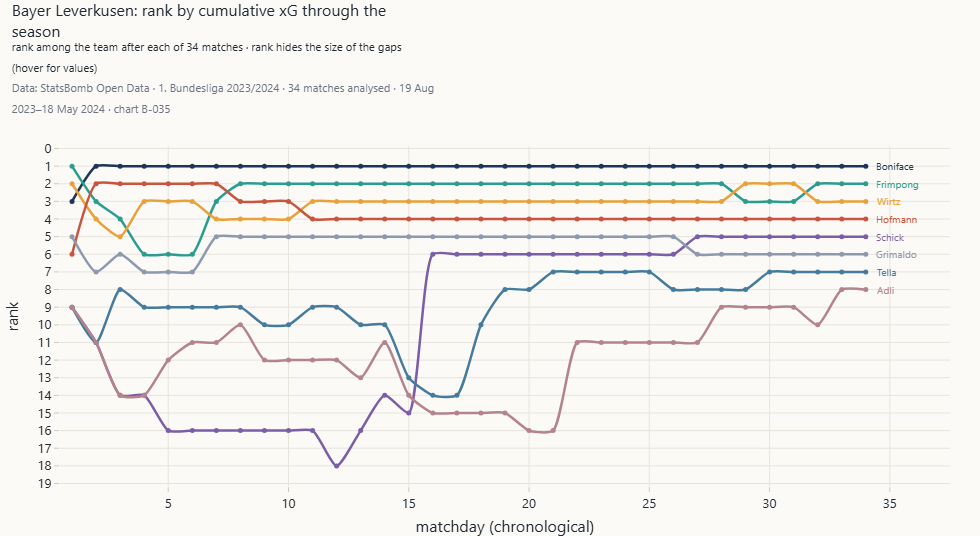

`B-035` Bump chart of rank changes · *Method:* Rank by cumulative xG after each match. · *Caveat:* Ranks hide the size of the gaps.

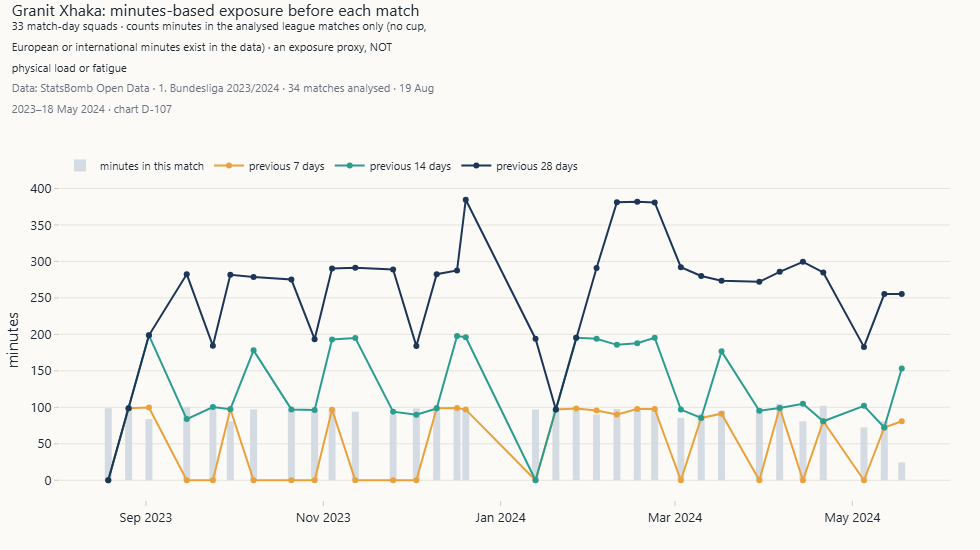

`D-107` Minutes-based exposure proxy · *Method:* Minutes in the previous 7, 14 and 28 days. · *Caveat:* An exposure proxy from league minutes only — not physical load or fatigue.

In [10]:
# Optional, heavier section — set RUN_ADVANCED_GALLERY = True in the setup cell to run it
if RUN_ADVANCED_GALLERY:
    show("L-264", ws)
    show("D-104", ws)
    show("D-106", ws)
    show("B-035", ws)
    show("D-107", ws, player_id=ws.default_player())